In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Set visualization style
sns.set_theme(style="whitegrid")

In [ ]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())


from pathlib import Path

file = Path("diabetic_data.csv")

print(file.exists())


# df = pd.read_csv("data/diabetic_data.csv")

# df.head()

Current folder:
/Users/eusilakitur/Desktop/Readmission-Project/notebooks

Files in this folder:
['data_overview.ipynb']
False


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [28]:
df = pd.read_csv(
    "../data/diabetic_data.csv",
    na_values="?",
    keep_default_na=False
)

df.head()

print("Number of rows and columns:", df.shape)

/var/folders/9q/s2m9sfg959b56zg_7x_s6sz40000gn/T/ipykernel_13667/1210303531.py:1: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


Number of rows and columns: (101766, 50)


In [27]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

print("\nPercentage of missing values per column:")

missing_percentage = (df.isnull().mean() * 100).round(2)

print(missing_percentage[missing_percentage > 0].sort_values(ascending=False))

race                  2273
weight               98569
payer_code           40256
medical_specialty    49949
diag_1                  21
diag_2                 358
diag_3                1423
dtype: int64

Percentage of missing values per column:
weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64


In [ ]:
display(df.dtypes)

for column in df.columns:
    if df[column].nunique() == 1:
        print(column)

# remove columns that contain only one value

df = df.drop(columns=["examide", "citoglipton"], errors="ignore")

# print(df.columns.tolist())

display(df.shape)


# remove records with invalid gender values
df = df[df["gender"] != "Unknown/Invalid"].copy()
df["gender"].value_counts()


encounter_id                 int64
patient_nbr                  int64
race                        object
gender                      object
age                         object
weight                      object
admission_type_id            int64
discharge_disposition_id     int64
admission_source_id          int64
time_in_hospital             int64
payer_code                  object
medical_specialty           object
num_lab_procedures           int64
num_procedures               int64
num_medications              int64
number_outpatient            int64
number_emergency             int64
number_inpatient             int64
diag_1                      object
diag_2                      object
diag_3                      object
number_diagnoses             int64
max_glu_serum               object
A1Cresult                   object
metformin                   object
repaglinide                 object
nateglinide                 object
chlorpropamide              object
glimepiride         

['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']


(101766, 48)

gender
Female    54708
Male      47055
Name: count, dtype: int64

In [42]:
display(df["readmitted"].value_counts())

# create a binary readmission target
df["readmitted_30"] = (df["readmitted"] == "<30").astype(int)

display(df["readmitted_30"].value_counts())

readmission_rate = df["readmitted_30"].mean() * 100

print("Readmission rate:", round(readmission_rate, 2), "%")

readmitted
NO     54861
>30    35545
<30    11357
Name: count, dtype: int64

readmitted_30
0    90406
1    11357
Name: count, dtype: int64

Readmission rate: 11.16 %


The target variable was converted into a binary classification outcome, where encounters resulting in readmission within 30 days were assigned a value of 1, while encounters with no readmission or readmission after 30 days were assigned a value of 0. Of the 101,763 encounters, 11,357 (11.16%) involved readmission within 30 days, indicating a substantial class imbalance.

In [49]:
# check the discharge disposition distribution
display(df["discharge_disposition_id"].value_counts().sort_index())

# discharge codes to exclude
excluded_codes = [11, 13, 14, 19, 20, 21]

# count encounters with these discharge codes
excluded_count = df[df["discharge_disposition_id"].isin(excluded_codes)].shape[0]

print("Encounters to exclude:", excluded_count)

# remove encounters with the selected discharge codes
df = df[~df["discharge_disposition_id"].isin(excluded_codes)].copy()

print("Updated dataset shape:", df.shape)

print(df["readmitted_30"].value_counts())

print("Updated readmission rate:",round(df["readmitted_30"].mean() * 100, 2),"%"
)

discharge_disposition_id
1     60232
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
12        3
15       63
16       11
17       14
18     3691
22     1992
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64

Encounters to exclude: 0
Updated dataset shape: (99340, 49)
readmitted_30
0    88026
1    11314
Name: count, dtype: int64
Updated readmission rate: 11.39 %


- Removed two constant columns.
- Removed three invalid gender records.
- Created a binary readmission target.
- Excluded the selected discharge disposition records.
- Reduced the dataset from 101,766 to 99,340 encounters.

In [52]:
# count the number of unique patients
unique_patients = df["patient_nbr"].nunique()

print("Unique patients:", unique_patients)
print("Total encounters:", len(df))

# count how many encounters each patient has
patient_visits = df["patient_nbr"].value_counts()

# count patients with more than one encounter
repeat_patients = (patient_visits > 1).sum()

print("Patients with multiple encounters:", repeat_patients)

#  how many patients have different numbers of encounters
patient_visits.value_counts().sort_index()

Unique patients: 69987
Total encounters: 99340
Patients with multiple encounters: 16341


count
1     53646
2     10218
3      3233
4      1354
5       691
6       338
7       192
8       112
9        67
10       41
11       22
12       18
13       11
14        5
15        9
16        4
17        3
18        7
19        2
20        6
21        1
22        2
23        3
28        1
40        1
Name: count, dtype: int64

### Handling Repeat Patient Encounters

The dataset contained 99,340 hospital encounters from 69,987 unique patients. Of these patients, 16,341 had multiple encounters, indicating that repeated hospital visits were relatively common.

To prevent data leakage, we will retain all encounters but use patient-level grouping when splitting the data into training and testing sets. This ensures that encounters belonging to the same patient do not appear in both sets. This approach also allows us to retain more observations than selecting only the first encounter for each patient.

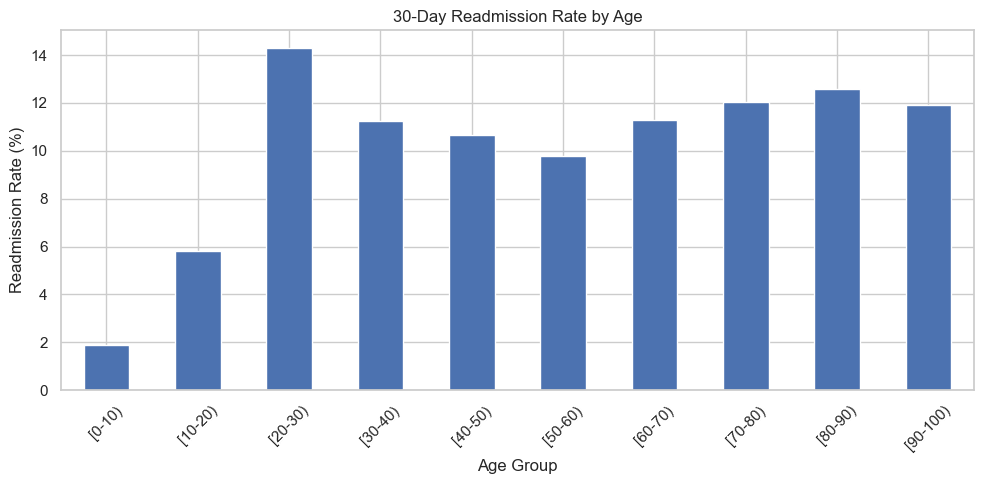

,encounters,readmissions,readmission_rate
age,,,
[0-10),160,3,1.88
[10-20),690,40,5.80
[20-30),1649,236,14.31
[30-40),3764,424,11.26
[40-50),9607,1024,10.66
[50-60),17060,1667,9.77
[60-70),22058,2493,11.30
[70-80),25329,3054,12.06
[80-90),16434,2065,12.57


In [55]:
age_readmission = df.groupby("age")["readmitted_30"].mean() * 100

age_readmission

age_readmission.plot(kind="bar", figsize=(10, 5))

plt.title("30-Day Readmission Rate by Age")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

age_summary = df.groupby("age")["readmitted_30"].agg(
    encounters="count",
    readmissions="sum",
    readmission_rate="mean"
)

age_summary["readmission_rate"] = (
    age_summary["readmission_rate"] * 100
).round(2)

age_summary

,encounters,readmissions,readmission_rate
race,,,
AfricanAmerican,18772,2149,11.45
Asian,628,65,10.35
Caucasian,74220,8556,11.53
Hispanic,2017,212,10.51
Other,1471,144,9.79
NaN,2232,188,8.42


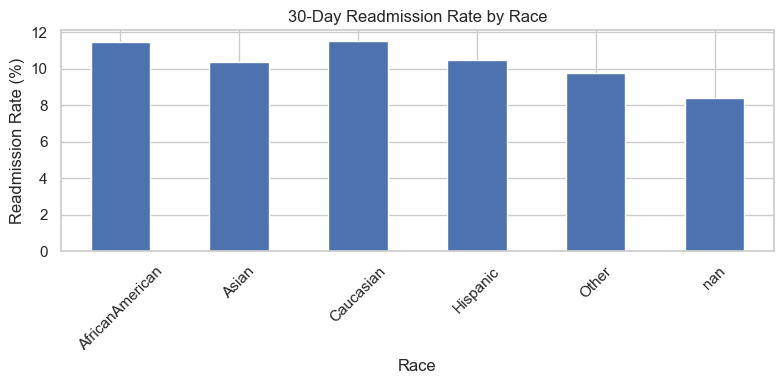

In [60]:
# readmission by race
race_summary = df.groupby("race", dropna=False)["readmitted_30"].agg(
    encounters="count",
    readmissions="sum",
    readmission_rate="mean"
)

race_summary["readmission_rate"] = (
    race_summary["readmission_rate"] * 100
).round(2)

display(race_summary)

# plot readmission rates by race
race_summary["readmission_rate"].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("30-Day Readmission Rate by Race")
plt.xlabel("Race")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Caucasian patients have the highest observed rate at 11.53%, closely followed by African American patients at 11.45%.

The difference between these two groups is only 0.08 percentage points.

The Asian and Hispanic groups have somewhat lower observed rates, but also substantially fewer encounters.

The missing-race category has the lowest observed rate, at 8.42%.

,encounters,readmissions,readmission_rate
gender,,,
Female,53454,6128,11.46
Male,45886,5186,11.30


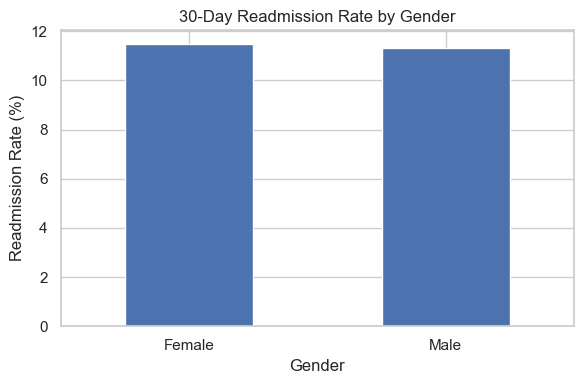

In [61]:
# readmission by gender
gender_summary = df.groupby("gender")["readmitted_30"].agg(
    encounters="count",
    readmissions="sum",
    readmission_rate="mean"
)

gender_summary["readmission_rate"] = (
    gender_summary["readmission_rate"] * 100
).round(2)

display(gender_summary)

# plot readmission rates by gender
gender_summary["readmission_rate"].plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("30-Day Readmission Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,encounters,readmissions,readmission_rate
admission_type_id,,,
1,52369,6194,11.83
2,18132,2058,11.35
3,18667,1958,10.49
4,10,1,10.00
5,4617,493,10.68
6,5207,583,11.20
7,18,0,0.00
8,320,27,8.44


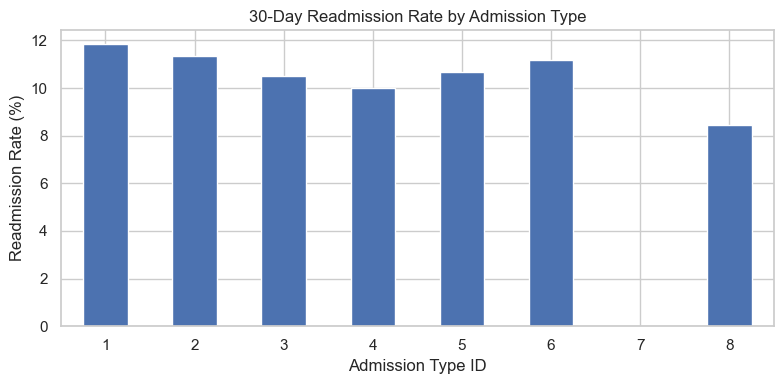

In [64]:
admission_summary = df.groupby("admission_type_id")["readmitted_30"].agg(
    encounters="count",
    readmissions="sum",
    readmission_rate="mean"
)

admission_summary["readmission_rate"] = (
    admission_summary["readmission_rate"] * 100
).round(2)

display(admission_summary)


admission_summary["readmission_rate"].plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("30-Day Readmission Rate by Admission Type")
plt.xlabel("Admission Type ID")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Emergency admissions have the highest observed readmission rate among the major admission categories.

Admission types 4 and 7 have very few encounters.

,encounters,readmissions,readmission_rate
discharge_disposition_id,,,
1,60232,5602,9.30
2,2128,342,16.07
3,13954,2046,14.66
4,815,104,12.76
5,1184,247,20.86
6,12902,1638,12.70
7,623,90,14.45
8,108,15,13.89
9,21,9,42.86


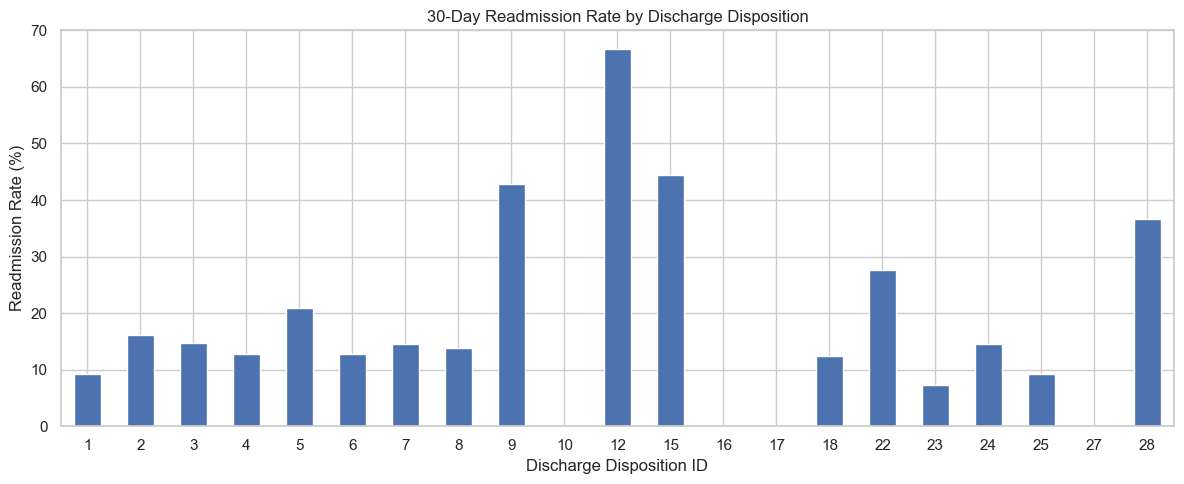

In [66]:
discharge_summary = df.groupby("discharge_disposition_id")["readmitted_30"].agg(
    encounters="count",
    readmissions="sum",
    readmission_rate="mean"
)

discharge_summary["readmission_rate"] = (
    discharge_summary["readmission_rate"] * 100
).round(2)

display(discharge_summary)

discharge_summary["readmission_rate"].plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("30-Day Readmission Rate by Discharge Disposition")
plt.xlabel("Discharge Disposition ID")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Readmission Rate by Discharge Disposition

Discharge disposition tells us where a patient went after leaving the hospital, such as home, a nursing facility, or a rehabilitation center.

From the graph, we can see that readmission rates differ depending on where patients were discharged.

Patients discharged home (code 1) had a relatively low readmission rate of **9.30%**, while patients discharged to rehabilitation facilities (code 22) had a much higher rate of **27.71%**. This could be because patients who need additional care after leaving the hospital may have more serious health conditions.

Some categories had very high readmission rates. For example, code 12 had a rate of **66.67%**, but this was based on only 3 encounters. This means we should be careful when interpreting high percentages from very small groups.

Overall, discharge disposition appears to be related to 30-day readmission. It could be a useful feature for our model. However, some categories have very few encounters, so we may need to combine similar categories during preprocessing.

,encounters,readmissions,readmission_rate
A1Cresult,,,
>7,3775,383,10.15
>8,8137,809,9.94
None,82506,9641,11.69
Norm,4922,481,9.77


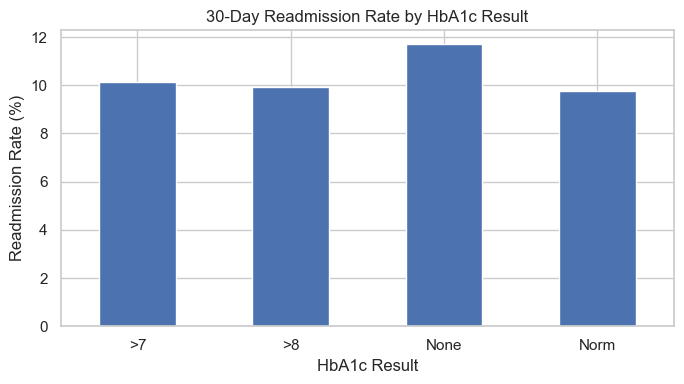

In [69]:
a1c_summary = df.groupby("A1Cresult")["readmitted_30"].agg(
    encounters="count",
    readmissions="sum",
    readmission_rate="mean"
)

a1c_summary["readmission_rate"] = (
    a1c_summary["readmission_rate"] * 100
).round(2)

display(a1c_summary)

a1c_summary["readmission_rate"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("30-Day Readmission Rate by HbA1c Result")
plt.xlabel("HbA1c Result")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Readmission Rate by HbA1c Result

HbA1c measures a patient's average blood sugar levels over the past two to three months.

From the results, patients without a recorded HbA1c test had the highest readmission rate at **11.69%**. Patients with HbA1c above 8% had a rate of **9.94%**, while those with normal results had the lowest rate at **9.77%**.

This is interesting because we might expect patients with higher blood sugar levels to have higher readmission rates. However, our results do not show a clear increase in readmission as HbA1c increases.

We also noticed that most encounters (about 83%) had no recorded HbA1c result. This makes the `None` category important to keep during preprocessing.

Overall, HbA1c results show some differences in readmission rates, but we cannot tell from this analysis whether HbA1c testing or blood sugar levels directly affect readmission.

In [70]:
numeric_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

df[numeric_cols].describe().round(2)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,99340.00,99340.00,99340.00,99340.00,99340.00,99340.00,99340.00,99340.00
mean,4.38,42.91,1.33,15.98,0.37,0.20,0.63,7.40
std,2.97,19.61,1.70,8.09,1.27,0.94,1.26,1.94
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
25%,2.00,31.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
max,14.00,132.00,6.00,81.00,42.00,76.00,21.00,16.00


In [71]:
numeric_comparison = df.groupby("readmitted_30")[numeric_cols].mean().round(2)

numeric_comparison.index = ["Not Readmitted Within 30 Days", "Readmitted Within 30 Days"]

numeric_comparison.T

,Not Readmitted Within 30 Days,Readmitted Within 30 Days
time_in_hospital,4.33,4.77
num_lab_procedures,42.74,44.22
num_procedures,1.34,1.28
num_medications,15.86,16.91
number_outpatient,0.36,0.44
number_emergency,0.18,0.36
number_inpatient,0.55,1.22
number_diagnoses,7.36,7.69


### Numerical Features and 30-Day Readmission

We compared the average values of numerical features for patients who were readmitted within 30 days and those who were not.

The biggest differences were in previous inpatient and emergency visits. Encounters followed by readmission had an average of **1.22 previous inpatient visits**, compared to **0.55** for encounters not followed by readmission. Previous emergency visits were also higher, at **0.36 compared to 0.18**.

Patients who were readmitted also spent slightly longer in the hospital (4.77 versus 4.33 days) and received slightly more medications (16.91 versus 15.86).

Overall, previous hospital and emergency visits appear to have a stronger relationship with readmission than some of the other numerical features. This suggests that a patient's history of healthcare use could be useful for predicting 30-day readmission.

,encounters,readmissions,readmission_rate
inpatient_group,,,
0,66242,5690,8.59
1,18984,2516,13.25
2,7300,1309,17.93
3,3271,688,21.03
4+,3543,1111,31.36


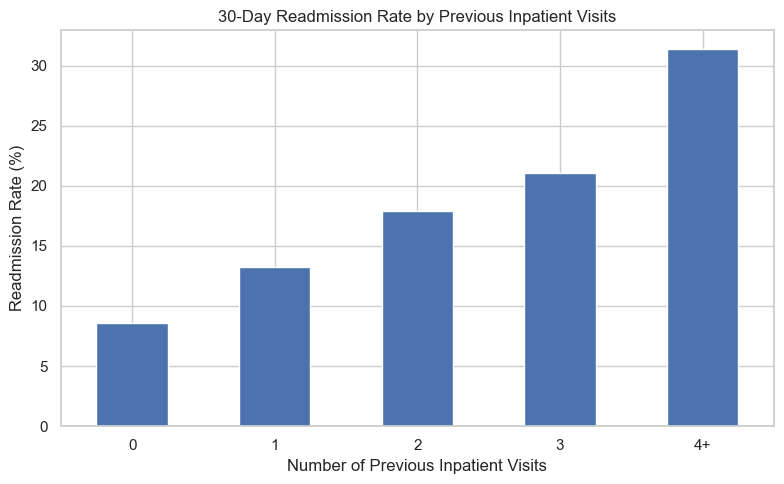

In [74]:
# group previous inpatient visits
df["inpatient_group"] = pd.cut(
    df["number_inpatient"],
    bins=[-1, 0, 1, 2, 3, float("inf")],
    labels=["0", "1", "2", "3", "4+"]
)

# calculate readmission rate for each group
inpatient_summary = df.groupby(
    "inpatient_group",
    observed=True
)["readmitted_30"].agg(
    encounters="count",
    readmissions="sum",
    readmission_rate="mean"
)

inpatient_summary["readmission_rate"] = (
    inpatient_summary["readmission_rate"] * 100
).round(2)

display(inpatient_summary)

inpatient_summary["readmission_rate"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("30-Day Readmission Rate by Previous Inpatient Visits")
plt.xlabel("Number of Previous Inpatient Visits")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Previous Inpatient Visits and Readmission

We grouped encounters based on the number of previous inpatient visits to see whether readmission rates changed as the number of visits increased.

The results show a clear pattern. Encounters with no previous inpatient visits had the lowest readmission rate at **8.59%**. The rate increased to **13.25%** for one previous visit, **17.93%** for two visits, and **21.03%** for three visits. Encounters with four or more previous visits had the highest rate at **31.36%**.

This suggests that patients with a history of frequent hospitalizations are more likely to be readmitted within 30 days. Previous inpatient visits could therefore be an important feature in our prediction model.

However, this is an association and does not mean that previous hospitalizations directly cause readmission.

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted_30
time_in_hospital,1.00,0.32,0.19,0.46,-0.01,-0.01,0.07,0.22,0.05
num_lab_procedures,0.32,1.00,0.05,0.27,-0.01,-0.00,0.04,0.15,0.02
num_procedures,0.19,0.05,1.00,0.38,-0.03,-0.04,-0.07,0.07,-0.01
num_medications,0.46,0.27,0.38,1.00,0.05,0.01,0.07,0.26,0.04
number_outpatient,-0.01,-0.01,-0.03,0.05,1.00,0.09,0.11,0.09,0.02
number_emergency,-0.01,-0.00,-0.04,0.01,0.09,1.00,0.27,0.06,0.06
number_inpatient,0.07,0.04,-0.07,0.07,0.11,0.27,1.00,0.10,0.17
number_diagnoses,0.22,0.15,0.07,0.26,0.09,0.06,0.10,1.00,0.05
readmitted_30,0.05,0.02,-0.01,0.04,0.02,0.06,0.17,0.05,1.00


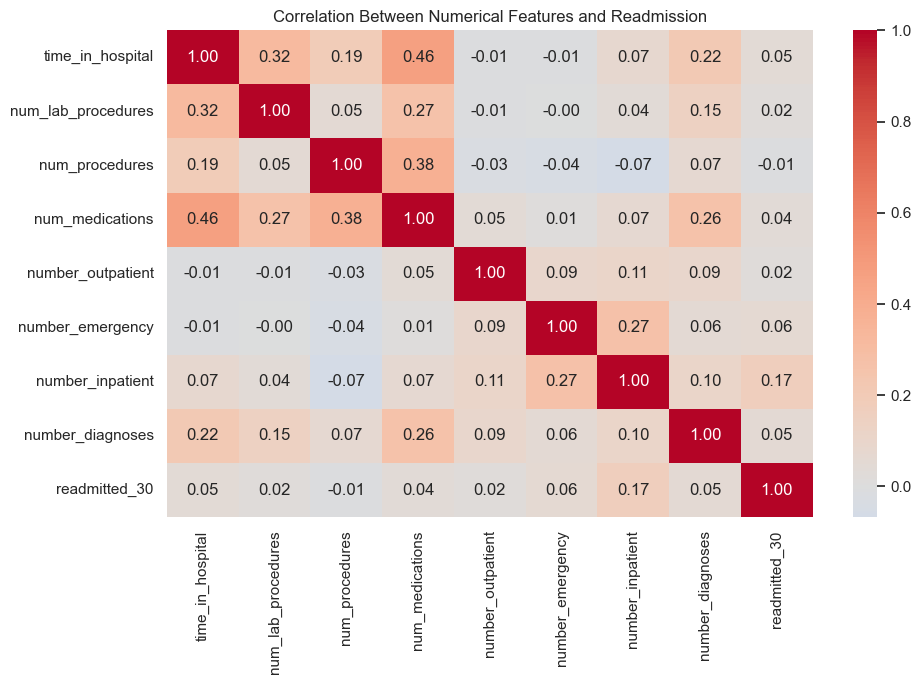

In [77]:
# include target in the correlation analysis
correlation_cols = numeric_cols + ["readmitted_30"]

correlation_matrix = df[correlation_cols].corr()

display(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Between Numerical Features and Readmission")
plt.tight_layout()
plt.show()

### Correlation Analysis

We created a correlation heatmap to see how the numerical features relate to each other and to 30-day readmission.

Previous inpatient visits had the strongest positive correlation with readmission (**0.17**). This supports our earlier finding that patients with more previous hospitalizations tend to have higher readmission rates.

However, all numerical features had relatively weak linear correlations with readmission. This suggests that no single numerical feature can strongly explain readmission on its own.

We also found that time spent in the hospital and number of medications had the highest correlation with each other (**0.46**). This could be because patients who stay longer in the hospital receive more medications.

Overall, these results suggest that predicting readmission may require combining several features rather than relying on one variable. We will keep these features for now and evaluate their usefulness during model training.

In [79]:
# make a working copy of our cleaned dataset
df_model = df.copy()

# remove columns we won't use
df_model = df_model.drop(
    columns=["weight", "payer_code"],
    errors="ignore"
)

# keep missing categories explicit
df_model["race"] = df_model["race"].fillna("Unknown")
df_model["medical_specialty"] = df_model["medical_specialty"].fillna("Missing")

# check the result
print("Dataset shape:", df_model.shape)

print("\nMissing values:")
print(df_model[["race", "medical_specialty"]].isna().sum())

Dataset shape: (99340, 48)

Missing values:
race                 0
medical_specialty    0
dtype: int64


In [84]:
age_mapping = {
    "[0-10)": 5,
    "[10-20)": 15,
    "[20-30)": 25,
    "[30-40)": 35,
    "[40-50)": 45,
    "[50-60)": 55,
    "[60-70)": 65,
    "[70-80)": 75,
    "[80-90)": 85,
    "[90-100)": 95
}

df_model["age_numeric"] = df_model["age"].map(age_mapping)

# check our conversion
print(df_model[["age", "age_numeric"]].head(10))

print("\nMissing converted ages:", df_model["age_numeric"].isna().sum())

display(df_model.shape)
display(df_model.head())

        age  age_numeric
0    [0-10)            5
1   [10-20)           15
2   [20-30)           25
3   [30-40)           35
4   [40-50)           45
5   [50-60)           55
6   [60-70)           65
7   [70-80)           75
8   [80-90)           85
9  [90-100)           95

Missing converted ages: 0


(99340, 49)

,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmitted_30,inpatient_group,age_numeric
0,2278392,8222157,Caucasian,Female,[0-10),6,25,1,1,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO,0,0,5
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,Missing,59,0,18,0,0,0,276,250.01,255,9,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30,0,0,15
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,Missing,11,5,13,2,0,1,648,250,V27,6,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO,0,1,25
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,Missing,44,1,16,0,0,0,8,250.43,403,7,None,None,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO,0,0,35
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,Missing,51,0,8,0,0,0,197,157,250,5,None,None,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO,0,0,45


In [88]:
def group_diagnosis(code):
    # handle missing diagnosis codes
    if pd.isna(code):
        return "Missing"

    # convert the code to a string
    code = str(code)

    # V and E codes go into Other
    if code.startswith(("V", "E")):
        return "Other"

    # convert the diagnosis code to a number
    try:
        code = float(code)
    except ValueError:
        return "Other"

    # diabetes
    if 250 <= code < 251:
        return "Diabetes"

    # circulatory diseases
    elif 390 <= code <= 459 or code == 785:
        return "Circulatory"

    # respiratory diseases
    elif 460 <= code <= 519 or code == 786:
        return "Respiratory"

    # digestive diseases
    elif 520 <= code <= 579 or code == 787:
        return "Digestive"

    # injury and poisoning
    elif 800 <= code <= 999:
        return "Injury"

    # musculoskeletal diseases
    elif 710 <= code <= 739:
        return "Musculoskeletal"

    # genitourinary diseases
    elif 580 <= code <= 629 or code == 788:
        return "Genitourinary"

    # neoplasms
    elif 140 <= code <= 239:
        return "Neoplasms"

    # everything else
    else:
        return "Other"


df_model["diag_1_group"] = df_model["diag_1"].apply(group_diagnosis)
df_model["diag_2_group"] = df_model["diag_2"].apply(group_diagnosis)
df_model["diag_3_group"] = df_model["diag_3"].apply(group_diagnosis)

# compare original codes with their new categories
display(df_model[
    ["diag_1", "diag_1_group",
     "diag_2", "diag_2_group",
     "diag_3", "diag_3_group"]
].head(10))
display(df_model["diag_1_group"].value_counts())

,diag_1,diag_1_group,diag_2,diag_2_group,diag_3,diag_3_group
0,250.83,Diabetes,NaN,Missing,NaN,Missing
1,276,Other,250.01,Diabetes,255,Other
2,648,Other,250,Diabetes,V27,Other
3,8,Other,250.43,Diabetes,403,Circulatory
4,197,Neoplasms,157,Neoplasms,250,Diabetes
5,414,Circulatory,411,Circulatory,250,Diabetes
6,414,Circulatory,411,Circulatory,V45,Other
7,428,Circulatory,492,Respiratory,250,Diabetes
8,398,Circulatory,427,Circulatory,38,Other
9,434,Circulatory,198,Neoplasms,486,Respiratory


diag_1_group
Circulatory        29680
Other              17793
Respiratory        13934
Digestive           9333
Diabetes            8661
Injury              6851
Genitourinary       5002
Musculoskeletal     4935
Neoplasms           3131
Missing               20
Name: count, dtype: int64

In [89]:
admission_mapping = {
    1: "Emergency",
    2: "Urgent",
    3: "Elective"
}

df_model["admission_type"] = (
    df_model["admission_type_id"]
    .map(admission_mapping)
    .fillna("Other/Unknown")
)

df_model["admission_type"].value_counts()

admission_type
Emergency        52369
Elective         18667
Urgent           18132
Other/Unknown    10172
Name: count, dtype: int64

In [104]:
df_model["discharge_disposition_id"] = df["discharge_disposition_id"]
df_model["admission_source_id"] = df["admission_source_id"]

def group_discharge(code):
    if code == 1:
        return "Home"

    elif code == 6:
        return "Home Health Care"

    elif code == 22:
        return "Rehabilitation"

    elif code in [2, 3, 4, 5, 10, 15, 23, 24, 27, 29, 30]:
        return "Facility/Transfer"

    elif code in [7, 8]:
        return "Against Advice/Home IV"

    elif code in [12, 16, 17]:
        return "Outpatient/Returning"

    elif code == 28:
        return "Psychiatric Facility"

    else:
        return "Other/Unknown"


df_model["discharge_group"] = (
    df_model["discharge_disposition_id"].apply(group_discharge)
)

df_model["discharge_group"].value_counts()



discharge_group
Home                      60232
Facility/Transfer         18615
Home Health Care          12902
Other/Unknown              4701
Rehabilitation             1992
Against Advice/Home IV      731
Psychiatric Facility        139
Outpatient/Returning         28
Name: count, dtype: int64

In [105]:

df_model["admission_source_id"].value_counts().sort_index()


def group_admission_source(code):
    if code == 7:
        return "Emergency Room"

    elif code == 1:
        return "Physician Referral"

    elif code in [2, 3]:
        return "Clinic/HMO Referral"

    elif code in [4, 5, 6, 10, 18, 22, 25, 26]:
        return "Facility Transfer"

    else:
        return "Other/Unknown"


df_model["admission_source"] = (
    df_model["admission_source_id"].apply(group_admission_source)
)

display(df_model["admission_source"].value_counts())



admission_source
Emergency Room         55848
Physician Referral     29167
Other/Unknown           6874
Facility Transfer       6185
Clinic/HMO Referral     1266
Name: count, dtype: int64

In [99]:
medication_cols = [
    "metformin", "repaglinide", "nateglinide",
    "chlorpropamide", "glimepiride", "acetohexamide",
    "glipizide", "glyburide", "tolbutamide",
    "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide",
    "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone"
]

df_model["num_meds_used"] = (
    df_model[medication_cols] != "No"
).sum(axis=1)

df_model["num_med_changes"] = (
    df_model[medication_cols].isin(["Up", "Down"])
).sum(axis=1)

display(df_model[["num_meds_used", "num_med_changes"]].describe()   )

display(df_model[
    ["insulin", "metformin", "num_meds_used", "num_med_changes"]
].head(10))

,num_meds_used,num_med_changes
count,99340.000000,99340.000000
mean,1.187367,0.287377
std,0.922431,0.487866
min,0.000000,0.000000
25%,1.000000,0.000000
50%,1.000000,0.000000
75%,2.000000,1.000000
max,6.000000,4.000000


,insulin,metformin,num_meds_used,num_med_changes
0,No,No,0,0
1,Up,No,1,1
2,No,No,1,0
3,Up,No,1,1
4,Steady,No,2,0
5,Steady,No,1,0
6,Steady,Steady,3,0
7,No,No,1,0
8,Steady,No,2,0
9,Steady,No,2,0


In [100]:
df_model["total_previous_visits"] = (
    df_model["number_outpatient"]
    + df_model["number_emergency"]
    + df_model["number_inpatient"]
)

display(df_model[
    ["number_outpatient", "number_emergency",
     "number_inpatient", "total_previous_visits"]
].head(10))

display(df_model["total_previous_visits"].describe())

,number_outpatient,number_emergency,number_inpatient,total_previous_visits
0,0,0,0,0
1,0,0,0,0
2,2,0,1,3
3,0,0,0,0
4,0,0,0,0
5,0,0,0,0
6,0,0,0,0
7,0,0,0,0
8,0,0,0,0
9,0,0,0,0


count    99340.000000
mean         1.198661
std          2.294240
min          0.000000
25%          0.000000
50%          0.000000
75%          2.000000
max         80.000000
Name: total_previous_visits, dtype: float64

In [107]:
columns_to_drop = [
    "age",
    "diag_1", "diag_2", "diag_3",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "inpatient_group",
    "readmitted"
]

df_model = df_model.drop(
    columns=[
        "discharge_disposition_id",
        "admission_source_id"
    ],
    errors="ignore"
)

print("Dataset shape:", df_model.shape)

print("Final dataset shape:", df_model.shape)

print("\nRemaining columns:")
print(df_model.columns.tolist())

print("\nMissing values:")
print(df_model.isna().sum()[df_model.isna().sum() > 0])

Dataset shape: (99340, 49)
Final dataset shape: (99340, 49)

Remaining columns:
['encounter_id', 'patient_nbr', 'race', 'gender', 'time_in_hospital', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted_30', 'age_numeric', 'diag_1_group', 'diag_2_group', 'diag_3_group', 'admission_type', 'discharge_group', 'admission_source', 'num_meds_used', 'num_med_changes', 'total_previous_visits']

Missing values:
Series([], dtype: int64)
